# E9 · Weather alignments compared directly, and the seasons used in development

Protocol addendum: [`protocolo_revision.md`](../protocolo_revision.md). Written after E1–E8, in response to external feedback; every result here is exploratory. Negative changes favour the first arm; intervals are 95% whole-season bootstrap intervals (20,000 draws, seeds paired).

- **Direct contrasts** between the three alignments: lag 0 (look-ahead), lag 1 and lag 2 (primary). A significant climate effect under one alignment and a non-significant one under another do not, by themselves, show that the alignments differ.
- **Season split**: the six seasons on which the b3 block was chosen during development (2010, 2015, 2016, 2022, 2023, 2026) against the other twelve.

In [1]:
import os
import sys
from pathlib import Path

os.environ.update({"DENGUEKAY_XGB_DEVICE": "cpu", "DENGUEKAY_XGB_NJOBS": "2", "OMP_NUM_THREADS": "2",
                   "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1", "MLFLOW_DISABLE_AGENT_HINT": "1"})
STUDY = Path.cwd().parent
sys.path.insert(0, str(STUDY / "code"))

import numpy as np
import pandas as pd

import common as c

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt

import experiments as ex

RES = c.OUTPUT / "resultados"
FIG = STUDY / "figures"
OTHER = tuple(s for s in c.SEASONS if s not in c.DECISION_SEASONS)
read_base = lambda name: pd.read_csv(c.OUTPUT / name, dtype={"ubigeo": str}, parse_dates=["semana_inicio", "origen_cierre"])

In [2]:
ARMS = {"lag 0": "b3_hist_geo", "lag 1": "b3_lag1", "lag 2": "b3_obs", "no climate": "historia_geo"}
sse = {k: ex.sse(c.read_arm(v, columns=ex.PRED_COLUMNS)) for k, v in ARMS.items()}
print("development seasons:", c.DECISION_SEASONS)
print("other seasons:", OTHER)

development seasons: (2010, 2015, 2016, 2022, 2023, 2026)
other seasons: (2009, 2011, 2012, 2013, 2014, 2017, 2018, 2019, 2020, 2021, 2024, 2025)


## Direct contrasts between alignments (18 seasons)

In [3]:
pairs = [("lag 0", "lag 2"), ("lag 0", "lag 1"), ("lag 1", "lag 2")]
direct = pd.concat([ex.contrast(sse[a], sse[b]).assign(comparison=f"{a} vs {b}") for a, b in pairs])
direct = direct[["comparison", "horizonte", "temporadas", "cambio_agrupado_%", "ic95_agrupado",
                 "cambio_igual_peso_%", "ic95_igual_peso", "temporadas_a_mejor"]]
direct.to_csv(RES / "e9_alineaciones_directas.csv", index=False)
direct.round(2)

,comparison,horizonte,temporadas,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,ic95_igual_peso,temporadas_a_mejor
0,lag 0 vs lag 2,2,18,-0.61,"(-1.0, -0.25)",-0.42,"(-0.84, 0.0)",13
1,lag 0 vs lag 2,3,18,-1.22,"(-1.73, -0.59)",-1.05,"(-1.78, -0.37)",14
2,lag 0 vs lag 2,4,18,-1.83,"(-2.65, -0.79)",-1.40,"(-2.62, -0.33)",14
0,lag 0 vs lag 1,2,18,-0.53,"(-0.87, -0.2)",-0.73,"(-1.39, -0.21)",12
1,lag 0 vs lag 1,3,18,-0.97,"(-1.34, -0.49)",-1.14,"(-2.07, -0.45)",15
2,lag 0 vs lag 1,4,18,-1.35,"(-1.94, -0.68)",-1.33,"(-2.33, -0.47)",14
0,lag 1 vs lag 2,2,18,-0.07,"(-0.2, 0.12)",0.24,"(-0.14, 0.81)",10
1,lag 1 vs lag 2,3,18,-0.33,"(-0.61, 0.04)",0.02,"(-0.36, 0.44)",10
2,lag 1 vs lag 2,4,18,-0.44,"(-0.77, -0.02)",-0.14,"(-0.47, 0.19)",10


## Development seasons against the other twelve

In [4]:
groups = {"18 seasons": c.SEASONS, "6 development seasons": c.DECISION_SEASONS, "12 other seasons": OTHER}
rows = []
for group, seasons in groups.items():
    sub = {k: v[v.temporada.isin(seasons)] for k, v in sse.items()}
    for lag in ("lag 0", "lag 1", "lag 2"):
        rows.append(ex.contrast(sub[lag], sub["no climate"]).assign(seasons=group, comparison=f"{lag} vs no climate"))
    rows.append(ex.contrast(sub["lag 0"], sub["lag 2"]).assign(seasons=group, comparison="lag 0 vs lag 2"))
split = pd.concat(rows)[["seasons", "comparison", "horizonte", "temporadas", "cambio_agrupado_%", "ic95_agrupado",
                         "cambio_igual_peso_%", "temporadas_a_mejor"]]
split.to_csv(RES / "e9_temporadas_desarrollo.csv", index=False)
split.round(2)

,seasons,comparison,horizonte,temporadas,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,temporadas_a_mejor
0,18 seasons,lag 0 vs no climate,2,18,-1.01,"(-2.05, -0.11)",-1.77,13
1,18 seasons,lag 0 vs no climate,3,18,-1.49,"(-2.99, -0.22)",-2.57,12
2,18 seasons,lag 0 vs no climate,4,18,-1.73,"(-3.67, -0.22)",-2.50,12
0,18 seasons,lag 1 vs no climate,2,18,-0.49,"(-1.48, 0.35)",-1.10,11
1,18 seasons,lag 1 vs no climate,3,18,-0.51,"(-2.05, 0.52)",-1.39,10
2,18 seasons,lag 1 vs no climate,4,18,-0.38,"(-2.52, 1.16)",-1.22,8
0,18 seasons,lag 2 vs no climate,2,18,-0.43,"(-1.46, 0.37)",-1.31,10
1,18 seasons,lag 2 vs no climate,3,18,-0.28,"(-1.89, 0.87)",-1.39,10
2,18 seasons,lag 2 vs no climate,4,18,0.04,"(-2.31, 1.7)",-1.15,10
0,18 seasons,lag 0 vs lag 2,2,18,-0.61,"(-1.0, -0.25)",-0.42,13


In [5]:
# The 18-season rows must equal E2 (e2_rezagos.csv)
e2 = pd.read_csv(RES / "e2_rezagos.csv")
e2 = e2[e2.seasons.eq("18 seasons")].assign(comparison=lambda d: d.arm.str.extract(r"^(lag \d)")[0] + " vs no climate")
check = split[split.seasons.eq("18 seasons")].merge(e2, on=["comparison", "horizonte"], suffixes=("", "_e2"))
assert len(check) == 9 and np.allclose(check["cambio_agrupado_%"], check["cambio_agrupado_%_e2"])
print("18-season contrasts identical to E2")

18-season contrasts identical to E2


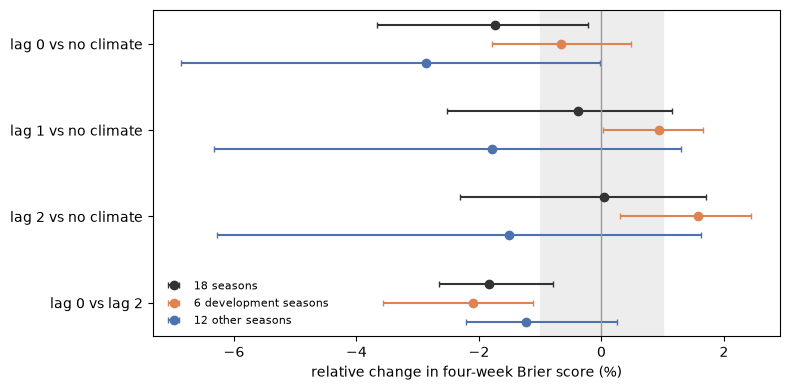

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
four = split[split.horizonte.eq(4)]
labels = ["lag 0 vs no climate", "lag 1 vs no climate", "lag 2 vs no climate", "lag 0 vs lag 2"]
colors = {"18 seasons": "#333333", "6 development seasons": "#DD8452", "12 other seasons": "#4C72B0"}
for i, (group, color) in enumerate(colors.items()):
    d = four[four.seasons.eq(group)].set_index("comparison").loc[labels]
    lo, hi = zip(*[eval(v) if isinstance(v, str) else v for v in d.ic95_agrupado])
    y = np.arange(len(labels)) + (i - 1) * 0.22
    ax.errorbar(d["cambio_agrupado_%"], y, xerr=[d["cambio_agrupado_%"] - lo, np.array(hi) - d["cambio_agrupado_%"]],
                fmt="o", color=color, label=group, capsize=2)
ax.axvline(0, color="0.6", lw=1)
ax.axvspan(-1, 1, color="0.93", zorder=0)
ax.set_yticks(range(len(labels)), labels)
ax.invert_yaxis()
ax.set_xlabel("relative change in four-week Brier score (%)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e9_alineaciones_temporadas.png", dpi=150)

## Reading

- **Direct contrasts.** Lag 0 (look-ahead) improved on the primary lag-2 alignment by 0.61%, 1.22% and 1.83% at two, three and four weeks (four-week interval 0.79% to 2.65%), and on lag 1 by 0.53%, 0.97% and 1.35%; every interval excludes zero. Lag 1 improved on lag 2 by 0.44% at four weeks (0.02% to 0.77%), so the freshest issue-time weather carries a small signal relative to the primary alignment.
- **Development seasons.** At four weeks, climate at lag 2 increased the Brier score by 1.57% (0.30% to 2.45%) in the six seasons on which the block was chosen (better in 2 of 6) and lowered it by 1.50% (interval −6.27% to +1.62%) in the other twelve (better in 8 of 12). The 18-season estimate (+0.04%) averages a penalty in the development seasons and a non-significant gain in the others. Selection on these seasons did not favour climate.
- **Look-ahead in the other twelve seasons.** In the twelve seasons not used to choose the climate block, lag 0 vs lag 2 was −1.23% (−2.21% to +0.26%): the same direction as over 18 seasons, with an interval that includes zero.